# A MicroGPT-Style MNIST Generator

Our implementation follows the structure of Karpathy's `microgpt.py` as closely as PyTorch allows and uses a KV cache. See https://karpathy.github.io/2026/02/12/microgpt/ for more details.


## 1. Dataset

A "document" is one 28×28 MNIST image with its class label.

In [1]:
import math, time
import torch
import matplotlib.pyplot as plt
from torchvision.datasets import MNIST

torch.manual_seed(42)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Dataset: documents are (image, label) pairs
train = MNIST('mnist_data', train=True, download=True)
test  = MNIST('mnist_data', train=False, download=True)
print(f"num docs: {len(train):,} | device: {DEVICE}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 485kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.66MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.98MB/s]

num docs: 60,000 | device: cuda


## 2. Tokenizer

Each image is read as 28 columns, left to right, and **one column is treated as one token**. A token is a 29-vector: 28 grey levels scaled to [0, 1], plus one slot that flags BOS (Beginning of Sequence). Grey levels are quantized to 16 values so the output can be a categorical.

In [2]:
n_levels = 16                  # grey levels per pixel
BOS = torch.zeros(29, device=DEVICE); BOS[28] = 1.0   # the BOS token: only the flag slot is on

def quantize(images_uint8):    # uint8 0..255 -> integer levels 0..15
    return (images_uint8.float() * (n_levels - 1) / 255).round().long()

def column_token(levels):      # integer levels [..., 28] -> token [..., 29]
    return torch.cat([levels.float() / (n_levels - 1), torch.zeros_like(levels[..., :1]).float()], dim=-1)

## 3. Parameters

`matrix(nout, nin)` mirrors microgpt's helper. `wte` has 29 inputs, so its last column is the **BOS embedding**.

In [3]:
n_layer = 3          # depth of the transformer neural network (number of layers)
n_embd = 128         # width of the network (embedding dimension)
block_size = 28      # context length: one position per image column
n_head = 4           # number of attention heads
head_dim = n_embd // n_head
n_mix = 4            # mixture components for the distribution of one column
n_out = n_mix + n_mix * 28 * n_levels   # mixture logits + (component, row, level) logits

matrix = lambda nout, nin, std=0.03: torch.randn(nout, nin, device=DEVICE).mul_(std).requires_grad_()
state_dict = {'wte': matrix(n_embd, 29), 'wpe': matrix(block_size, n_embd, 0.02),
              'wde': matrix(10, n_embd, 0.02), 'lm_head': matrix(n_out, n_embd)}
for i in range(n_layer):
    state_dict[f'layer{i}.attn_wq'] = matrix(n_embd, n_embd)
    state_dict[f'layer{i}.attn_wk'] = matrix(n_embd, n_embd)
    state_dict[f'layer{i}.attn_wv'] = matrix(n_embd, n_embd)
    state_dict[f'layer{i}.attn_wo'] = matrix(n_embd, n_embd)
    state_dict[f'layer{i}.mlp_fc1'] = matrix(4 * n_embd, n_embd)
    state_dict[f'layer{i}.mlp_fc2'] = matrix(n_embd, 4 * n_embd)
state_dict['lm_bias'] = torch.zeros(n_out, device=DEVICE).requires_grad_()   # output bias (vector)
params = list(state_dict.values())
print(f"num params: {sum(p.numel() for p in params)}")

num params: 830084


## 4. Architecture

`gpt(tokens, labels, pos_id, keys, values)` maps new tokens and the cached past to logits over the next column. It follows GPT-2 with the same departures as microgpt: RMSNorm in place of LayerNorm, no biases in the blocks, ReLU in place of GeLU.

- `tokens` is `[B, T, 29]`, occupying positions `pos_id … pos_id+T-1`.
- `keys[li]` and `values[li]` are lists of cached chunks for layer `li`. Each call appends its new k and v, as in microgpt (`keys[li].append(k)`), and attention runs over the concatenation.
- A query at position *i* may see keys at positions ≤ *i*. The mask is `triu(S-T+1)` over `[T, S]`. For `T=1` it masks nothing, which is the microgpt case.
- `labels` adds a class embedding at every position, so generation is class-conditional.

In [4]:
def linear(x, w):
    return x @ w.T

def softmax(logits):
    max_val = logits.max(dim=-1, keepdim=True).values.detach()
    exps = (logits - max_val).exp()
    return exps / exps.sum(dim=-1, keepdim=True)

def log_softmax(logits):
    max_val = logits.max(dim=-1, keepdim=True).values.detach()
    shifted = logits - max_val
    return shifted - shifted.exp().sum(dim=-1, keepdim=True).log()

def rmsnorm(x):
    ms = x.square().mean(dim=-1, keepdim=True)
    scale = (ms + 1e-5) ** -0.5
    return x * scale

def gpt(tokens, labels, pos_id, keys, values):
    b, T, _ = tokens.shape
    S = pos_id + T                                        # keys visible after appending this chunk
    tok_emb = linear(tokens, state_dict['wte'])           # token embedding (column, or BOS)
    pos_emb = state_dict['wpe'][pos_id:pos_id + T]        # position embedding
    cls_emb = state_dict['wde'][labels][:, None, :]       # class embedding (digit)
    x = rmsnorm(tok_emb + pos_emb + cls_emb)              # joint embedding; the norm is not redundant (see microgpt)
    mask = torch.ones(T, S, dtype=torch.bool, device=x.device).triu(S - T + 1)   # True where a key lies in the future
    split = lambda y: y.reshape(b, T, n_head, head_dim).transpose(1, 2)           # [B, T, E] -> [B, H, T, hd]

    for li in range(n_layer):
        # 1) Multi-head Attention block
        x_residual = x
        x = rmsnorm(x)
        q = split(linear(x, state_dict[f'layer{li}.attn_wq']))
        k = split(linear(x, state_dict[f'layer{li}.attn_wk']))
        v = split(linear(x, state_dict[f'layer{li}.attn_wv']))
        keys[li].append(k)
        values[li].append(v)
        k_all, v_all = torch.cat(keys[li], dim=2), torch.cat(values[li], dim=2)
        assert k_all.shape[2] == S, 'cache length must equal pos_id + T'
        attn_logits = (q @ k_all.transpose(-2, -1)) / head_dim ** 0.5
        attn_weights = softmax(attn_logits.masked_fill(mask, -torch.inf))
        x_attn = (attn_weights @ v_all).transpose(1, 2).reshape(b, T, n_embd)
        x = linear(x_attn, state_dict[f'layer{li}.attn_wo'])
        x = x + x_residual
        # 2) MLP block
        x_residual = x
        x = rmsnorm(x)
        x = linear(x, state_dict[f'layer{li}.mlp_fc1'])
        x = x.relu()
        x = linear(x, state_dict[f'layer{li}.mlp_fc2'])
        x = x + x_residual

    x = rmsnorm(x)                                        # final norm (microgpt has none; kept from the earlier notebook)
    out = linear(x, state_dict['lm_head']) + state_dict['lm_bias']
    mixture = out[..., :n_mix]                                                # [B, T, K]  which component
    pixels = out[..., n_mix:].reshape(b, T, n_mix, 28, n_levels)              # [B, T, K, 28 rows, levels]
    return mixture, pixels

## 5. Optimizer

Adam and its buffers, as in microgpt: one `m` and one `v` per parameter, bias-corrected, with linear learning-rate decay. Gradient clipping is added on top.

In [5]:
learning_rate, beta1, beta2, eps_adam = 3e-4, 0.9, 0.95, 1e-8
max_grad_norm = 1.0
m = [torch.zeros_like(p) for p in params]   # first moment buffer
v = [torch.zeros_like(p) for p in params]   # second moment buffer

## 6. Verify the KV cache before training

`gpt` has a single code path, so this check compares the **parallel call** (`T=28`, empty cache) with **28 incremental calls** (`T=1`, growing cache). It runs before training so any error shows up early. The outputs should agree to floating-point rounding, and each layer's cache should hold one k and one v per position.

In [6]:
def new_cache():
    return [[] for _ in range(n_layer)], [[] for _ in range(n_layer)]

check_labels = torch.tensor([0, 7], device=DEVICE)
check_cols = torch.randint(n_levels, (2, 28, 28), device=DEVICE)                   # [B, column, row] levels
check_tokens = torch.cat([BOS.expand(2, 1, 29), column_token(check_cols[:, :-1])], dim=1)

with torch.no_grad():
    keys, values = new_cache()
    full_mix, full_pix = gpt(check_tokens, check_labels, 0, keys, values)          # all 28 positions at once
    keys, values = new_cache()
    max_diff = 0.0
    for t in range(28):                                                            # one position at a time
        mix_t, pix_t = gpt(check_tokens[:, t:t + 1], check_labels, t, keys, values)
        max_diff = max(max_diff, (mix_t[:, 0] - full_mix[:, t]).abs().max().item(),
                                 (pix_t[:, 0] - full_pix[:, t]).abs().max().item())
        assert all(torch.cat(keys[li], 2).shape == (2, n_head, t + 1, head_dim) for li in range(n_layer))
    assert max_diff < 1e-4, f'incremental/parallel mismatch: {max_diff:.3g}'
print(f'KV cache verified: max logit difference {max_diff:.2e}')
del check_tokens, full_mix, full_pix, keys, values

KV cache verified: max logit difference 7.15e-07


## 7. Inference

Sampling follows microgpt's loop: start from BOS, call `gpt`, turn logits into probabilities with `softmax`, sample, feed the sample back. Here a sample takes two draws: first the mixture component, then all 28 rows from that component's categoricals. `use_cache=False` recomputes the whole prefix from an empty cache at every step. It is the reference for correctness and timing, since the cached path computes the same distribution.

In [7]:
@torch.no_grad()
def generate(labels, use_cache=True, temperature=1.0):
    b = len(labels)
    keys, values = new_cache()
    tokens = BOS.expand(b, 1, 29)                       # [B, positions so far, 29]
    columns = []
    for pos_id in range(block_size):
        if use_cache:                                   # only the newest token goes through the network
            mixture, pixels = gpt(tokens[:, -1:], labels, pos_id, keys, values)
        else:                                           # reference: whole prefix, fresh cache
            k0, v0 = new_cache()
            mixture, pixels = gpt(tokens, labels, 0, k0, v0)
        mix_probs = softmax(mixture[:, -1] / temperature)                              # [B, K]
        component = torch.multinomial(mix_probs, 1)[:, 0]                              # sample a component
        pix_probs = softmax(pixels[torch.arange(b, device=labels.device), -1, component] / temperature)  # [B, 28, levels]
        column = torch.multinomial(pix_probs.reshape(-1, n_levels), 1).reshape(b, 28)  # sample 28 rows
        columns.append(column)
        tokens = torch.cat([tokens, column_token(column)[:, None]], dim=1)
    return torch.stack(columns, dim=2).float() / (n_levels - 1)    # [B, rows, columns], values in [0, 1]

torch.manual_seed(123); a = generate(check_labels, use_cache=True)
torch.manual_seed(123); b_ = generate(check_labels, use_cache=False)
print('cached and full-prefix sampling identical:', torch.equal(a, b_), '| max diff', (a - b_).abs().max().item())

cached and full-prefix sampling identical: True | max diff 0.0


## 8. Training

Each step takes one batch of "documents" and builds `tokens = [BOS] + columns`. The BOS token and the 27 leading columns are the inputs, and the 28 columns are the targets. It then runs the forward pass to the loss, calls `loss.backward()`, and applies Adam.

The loss is the negative log-likelihood of a column under the mixture, averaged over columns and divided by 28, so it is reported in nats per pixel:

`p(column) = Σ_k π_k Π_row softmax(ℓ_{k,row})[level]`

In [8]:
num_steps = 10000 if DEVICE == 'cuda' else 50
batch_size = 128 if DEVICE == 'cuda' else 16

for step in range(num_steps):

    # Take a batch of documents and tokenize: [BOS] + the columns of each image
    ids = torch.randint(len(train), (batch_size,))
    images = quantize(train.data[ids].to(DEVICE))                  # [B, rows, cols] levels
    labels = train.targets[ids].to(DEVICE)
    cols = images.transpose(1, 2).contiguous()                     # [B, 28 columns, 28 rows]
    tokens = torch.cat([BOS.expand(batch_size, 1, 29), column_token(cols[:, :-1])], dim=1)

    # Forward the token sequences through the model, building up the graph all the way to the loss
    keys, values = new_cache()
    mixture, pixels = gpt(tokens, labels, 0, keys, values)
    target = cols[:, :, None, :, None].expand(-1, -1, n_mix, -1, -1)
    log_pixel = log_softmax(pixels).gather(-1, target).squeeze(-1)                    # [B, T, K, 28]
    log_column = torch.logsumexp(log_softmax(mixture) + log_pixel.sum(-1), dim=-1)    # [B, T]
    loss = -log_column.mean() / 28                                                    # nats / pixel

    # Backward the loss, calculating the gradients with respect to all model parameters
    for p in params: p.grad = None
    loss.backward()

    # Adam optimizer update (with gradient clipping and linear learning rate decay)
    with torch.no_grad():
        gnorm = torch.sqrt(sum(p.grad.square().sum() for p in params))
        clip = (max_grad_norm / (gnorm + 1e-6)).clamp(max=1.0)
        lr_t = learning_rate * (1 - step / num_steps)
        for i, p in enumerate(params):
            g = p.grad * clip
            m[i].mul_(beta1).add_(g, alpha=1 - beta1)
            v[i].mul_(beta2).addcmul_(g, g, value=1 - beta2)
            m_hat = m[i] / (1 - beta1 ** (step + 1))
            v_hat = v[i] / (1 - beta2 ** (step + 1))
            p.addcdiv_(m_hat, v_hat.sqrt() + eps_adam, value=-lr_t)

    if step == 0 or (step + 1) % 500 == 0 or step + 1 == num_steps:
        print(f"step {step+1:5d} / {num_steps:5d} | loss {loss.item():.4f} nats/pixel")

step     1 / 10000 | loss 2.7947 nats/pixel
step   500 / 10000 | loss 0.4335 nats/pixel
step  1000 / 10000 | loss 0.4223 nats/pixel
step  1500 / 10000 | loss 0.3819 nats/pixel
step  2000 / 10000 | loss 0.3827 nats/pixel
step  2500 / 10000 | loss 0.3747 nats/pixel
step  3000 / 10000 | loss 0.3878 nats/pixel
step  3500 / 10000 | loss 0.3640 nats/pixel
step  4000 / 10000 | loss 0.3680 nats/pixel
step  4500 / 10000 | loss 0.3666 nats/pixel
step  5000 / 10000 | loss 0.3468 nats/pixel
step  5500 / 10000 | loss 0.3559 nats/pixel
step  6000 / 10000 | loss 0.3682 nats/pixel
step  6500 / 10000 | loss 0.3589 nats/pixel
step  7000 / 10000 | loss 0.3667 nats/pixel
step  7500 / 10000 | loss 0.3498 nats/pixel
step  8000 / 10000 | loss 0.3510 nats/pixel
step  8500 / 10000 | loss 0.3645 nats/pixel
step  9000 / 10000 | loss 0.3558 nats/pixel
step  9500 / 10000 | loss 0.3471 nats/pixel
step 10000 / 10000 | loss 0.3622 nats/pixel


## 9. Held-out likelihood

The training loss above is a noisy single-batch value. This cell averages the same loss over the first 2,000 test images, so it is a proper held-out figure in nats per pixel.

In [9]:
@torch.no_grad()
def test_nll(n=2000, bs=250):
    n = min(n, len(test))
    total = 0.0
    for i in range(0, n, bs):
        images = quantize(test.data[i:i + bs].to(DEVICE)); labels = test.targets[i:i + bs].to(DEVICE)
        cols = images.transpose(1, 2).contiguous()
        tokens = torch.cat([BOS.expand(len(cols), 1, 29), column_token(cols[:, :-1])], dim=1)
        keys, values = new_cache()
        mixture, pixels = gpt(tokens, labels, 0, keys, values)
        target = cols[:, :, None, :, None].expand(-1, -1, n_mix, -1, -1)
        log_pixel = log_softmax(pixels).gather(-1, target).squeeze(-1)
        log_column = torch.logsumexp(log_softmax(mixture) + log_pixel.sum(-1), dim=-1)
        total += -log_column.mean().item() / 28 * len(cols)
    return total / n
print(f'held-out NLL on the first 2000 test images: {test_nll():.4f} nats/pixel')

held-out NLL on the first 2000 test images: 0.3571 nats/pixel


## 10. Real MNIST vs newly generated images

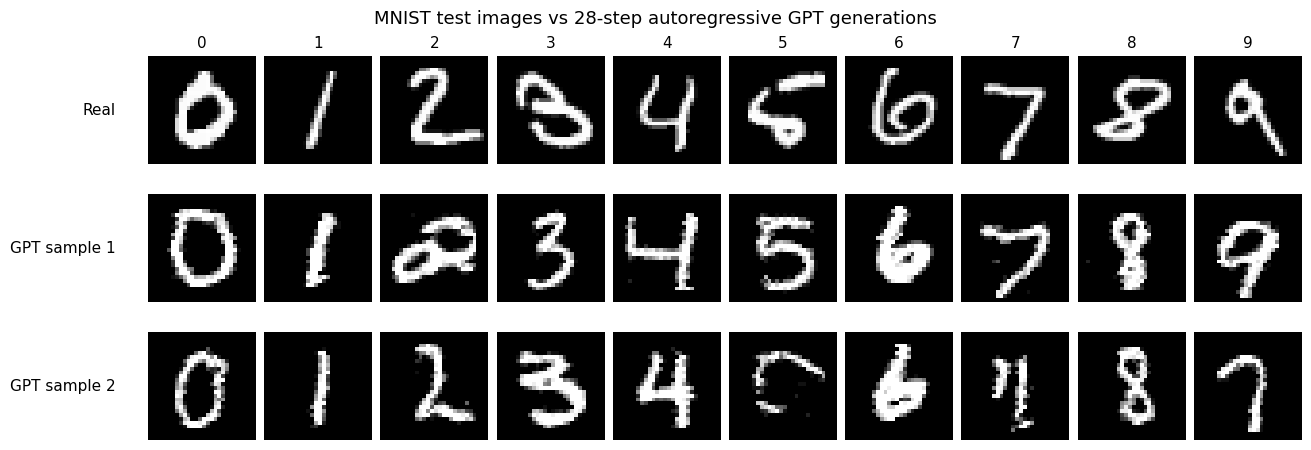

In [10]:
labels = torch.arange(10, device=DEVICE).repeat(2)    # 2 fresh images per class
new_images = generate(labels).cpu()
real_idx = [int((test.targets == digit).nonzero()[0, 0]) for digit in range(10)]
real_images = test.data[real_idx].float() / 255.0

fig, axes = plt.subplots(3, 10, figsize=(13, 4.5), constrained_layout=True)
for digit in range(10):
    axes[0, digit].imshow(real_images[digit], cmap='gray', vmin=0, vmax=1)
    axes[1, digit].imshow(new_images[digit], cmap='gray', vmin=0, vmax=1)
    axes[2, digit].imshow(new_images[digit + 10], cmap='gray', vmin=0, vmax=1)
    axes[0, digit].set_title(str(digit), fontsize=11)
    for row in range(3):
        axes[row, digit].axis('off')
for row, text in enumerate(('Real', 'GPT sample 1', 'GPT sample 2')):
    axes[row, 0].text(-0.3, 0.5, text, transform=axes[row, 0].transAxes, ha='right', va='center', fontsize=11)
fig.suptitle('MNIST test images vs 28-step autoregressive GPT generations', fontsize=13)
plt.savefig('mnist_real_vs_generated.png', dpi=160, bbox_inches='tight')
plt.show()